# PCA: Sind die Hauptkomponenten gewichtete Summen der Merkmale?

**Behauptung.** Bei PCA ist jede Hauptkomponente eine gewichtete Summe aller (standardisierten) Merkmale. Die Gewichte stehen in `pca.components_`. Die Dimensionsreduktion ist damit eine Matrixmultiplikation:

$$Z = (X_z - \mu)\,W_k^\top \qquad W_k = \texttt{pca.components\_}\ (k \times p)$$

Nach dem Standardisieren ist $\mu = 0$.

Das Notebook prüft diese Behauptung am Wein-Datensatz (178 Weine, 13 Merkmale) mit scikit-learn. Jede Zelle vergleicht die Rechnung von Hand mit `PCA.transform`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

wine = load_wine(as_frame=True)
X = wine.data                      # 13 Merkmale; die Sorte (wine.target) wird nicht verwendet
X_z = StandardScaler().fit_transform(X)
print(X.shape)

(178, 13)


## 1. PCA mit scikit-learn, 3 Komponenten

In [2]:
pca = PCA(n_components=3).fit(X_z)
Z = pca.transform(X_z)             # 178 × 3

W = pd.DataFrame(pca.components_, index=["PC1", "PC2", "PC3"], columns=X.columns)
print("Erklärte Varianz:", (pca.explained_variance_ratio_ * 100).round(1), "%")
W.round(2)

Erklärte Varianz: [36.2 19.2 11.1] %


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
PC1,0.14,-0.25,-0.00,-0.24,0.14,0.39,0.42,-0.30,0.31,-0.09,0.30,0.38,0.29
PC2,0.48,0.22,0.32,-0.01,0.30,0.07,-0.00,0.03,0.04,0.53,-0.28,-0.16,0.36
PC3,-0.21,0.09,0.63,0.61,0.13,0.15,0.15,0.17,0.15,-0.14,0.09,0.17,-0.13


`pca.components_` hat eine Zeile pro Komponente und eine Spalte pro Merkmal: 3 × 13 Gewichte.

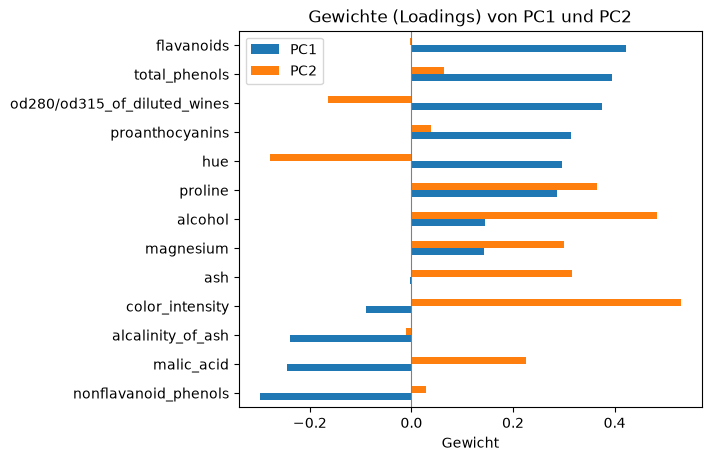

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
W.T[["PC1", "PC2"]].sort_values("PC1").plot.barh(ax=ax)
ax.axvline(0, color="grey", lw=0.8)
ax.set(title="Gewichte (Loadings) von PC1 und PC2", xlabel="Gewicht")
plt.show()

## 2. Ein Wein, von Hand: PC1 als gewichtete Summe der 13 Merkmale

In [4]:
i = 0
rechnung = pd.DataFrame({
    "z-Wert": X_z[i],
    "Gewicht PC1": pca.components_[0],
})
rechnung["Produkt"] = rechnung["z-Wert"] * rechnung["Gewicht PC1"]
rechnung.index = X.columns
display(rechnung.round(3))
print("Summe der Produkte:   ", round(rechnung["Produkt"].sum(), 6))
print("pca.transform, PC1:   ", round(Z[i, 0], 6))

,z-Wert,Gewicht PC1,Produkt
alcohol,1.519,0.144,0.219
malic_acid,-0.562,-0.245,0.138
ash,0.232,-0.002,-0.000
alcalinity_of_ash,-1.170,-0.239,0.280
magnesium,1.914,0.142,0.272
total_phenols,0.809,0.395,0.319
flavanoids,1.035,0.423,0.438
nonflavanoid_phenols,-0.660,-0.299,0.197
proanthocyanins,1.225,0.313,0.384
color_intensity,0.252,-0.089,-0.022


Summe der Produkte:    3.316751
pca.transform, PC1:    3.316751


## 3. Alle Weine und alle 3 Komponenten: eine Matrixmultiplikation

In [5]:
Z_hand = (X_z - pca.mean_) @ pca.components_.T     # pca.mean_ ist hier ≈ 0
print("Form:", Z_hand.shape)
print("identisch mit pca.transform:", np.allclose(Z_hand, Z))
print("grösste Abweichung:", np.abs(Z_hand - Z).max())

Form: (178, 3)
identisch mit pca.transform: True
grösste Abweichung: 8.881784197001252e-16


## 4. Woher kommen die Gewichte? Eigenvektoren der Kovarianzmatrix

In [6]:
cov = np.cov(X_z, rowvar=False)                    # 13 × 13
eigval, eigvec = np.linalg.eigh(cov)
order = np.argsort(eigval)[::-1][:3]

# Vorzeichen eines Eigenvektors ist willkürlich, darum Beträge vergleichen
print("Gewichte = Eigenvektoren:", np.allclose(np.abs(eigvec[:, order].T), np.abs(pca.components_)))
print("Varianz je PC = Eigenwerte:", np.allclose(eigval[order], pca.explained_variance_))
print("Gewichte je PC haben Länge 1, PCs stehen senkrecht (W·Wᵀ = I):",
      np.allclose(pca.components_ @ pca.components_.T, np.eye(3)))

Gewichte = Eigenvektoren: True
Varianz je PC = Eigenwerte: True
Gewichte je PC haben Länge 1, PCs stehen senkrecht (W·Wᵀ = I): True


## 5. Was bei der Reduktion verloren geht

Mit allen 13 Komponenten ist die Transformation nur eine Drehung, nichts geht verloren. Mit 3 Komponenten fehlt der Rest der Varianz. `inverse_transform` rechnet $Z\,W_k + \mu$ zurück.

In [7]:
for k in (3, 13):
    p = PCA(n_components=k).fit(X_z)
    X_back = p.inverse_transform(p.transform(X_z))
    fehler = ((X_z - X_back) ** 2).sum() / (X_z ** 2).sum()
    print(f"k = {k:2d}: erklärte Varianz {p.explained_variance_ratio_.sum():.1%}, "
          f"Rekonstruktionsfehler {fehler:.1%}")

k =  3: erklärte Varianz 66.5%, Rekonstruktionsfehler 33.5%
k = 13: erklärte Varianz 100.0%, Rekonstruktionsfehler 0.0%


## Fazit und Fragen

- `pca.transform` rechnet für jeden Wein **pro Komponente eine gewichtete Summe** der 13 standardisierten Merkmale (Abschnitte 2 und 3).
- Die Gewichte sind die **Eigenvektoren der Kovarianzmatrix**, die Eigenwerte sind die Varianzen der Komponenten (Abschnitt 4).
- Die Reduktion entsteht, indem man nur die ersten k Komponenten behält. Der Rest der Varianz geht verloren (Abschnitt 5).

**Fragen:**
1. Stimmt diese Sicht auf PCA, also dass jede Komponente eine Linearkombination aller Merkmale ist und `components_` die Gewichte enthält?
2. Darf man eine Komponente über ihre grössten Gewichte deuten (hier PC1 ≈ Phenole/Flavanoide, PC2 ≈ Farbintensität/Alkohol)?
3. Gilt das so nicht für t-SNE oder UMAP, weil diese keine linearen Gewichte liefern?